# 2A.  The dataset has yet to be analyzed. Analyze it & state any discovered issues! Also, handle the  issues found in the dataset & provide reasons for your methods in dealing with each issue!

Import library yang dibutuhkan

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

Import Dataset

In [102]:
df = pd.read_parquet("2B.parquet")

df.head()


,Sales_ID,name,year,selling_price,Region,State or Province,City,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,4333,Maruti,2018,6000.0,Central,Nebraska,Norfolk,Petrol,Dealer,Automatic,First_Owner,22.0,1197,81.80,113Nm@ 4200rpm,5
1,5562,Tata,2012,1400.0,Central,Illinois,Bloomington,Diesel,Individual,Manual,Fourth_Above_Owner,19.09,1396,69.00,135Nm@ 2500rpm,5
2,6854,Chevrolet,2015,4340.0,East,New York,Schenectady,Diesel,Individual,Manual,First_Owner,13.58,2499,72.40,171Nm@ 1800rpm,10
3,8113,Ford,2018,7460.0,South,North Carolina,Mooresville,Diesel,Individual,Manual,First_Owner,24.4,1498,98.63,215Nm@ 1750-3000rpm,5
4,6986,Tata,2017,3700.0,East,Maryland,Silver Spring,Petrol,Individual,Manual,First_Owner,17.57,1193,88.70,140Nm@ 1500-4000rpm,5


**DATA OVERVIEW**

Memahami struktur dataset dan mengidentifikasi potensi masalah sejak dini

1. Lihat dataset

In [103]:
df.head()
#melihat beberapa baris pertama dataset untuk memahami bentuk data

,Sales_ID,name,year,selling_price,Region,State or Province,City,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,4333,Maruti,2018,6000.0,Central,Nebraska,Norfolk,Petrol,Dealer,Automatic,First_Owner,22.0,1197,81.80,113Nm@ 4200rpm,5
1,5562,Tata,2012,1400.0,Central,Illinois,Bloomington,Diesel,Individual,Manual,Fourth_Above_Owner,19.09,1396,69.00,135Nm@ 2500rpm,5
2,6854,Chevrolet,2015,4340.0,East,New York,Schenectady,Diesel,Individual,Manual,First_Owner,13.58,2499,72.40,171Nm@ 1800rpm,10
3,8113,Ford,2018,7460.0,South,North Carolina,Mooresville,Diesel,Individual,Manual,First_Owner,24.4,1498,98.63,215Nm@ 1750-3000rpm,5
4,6986,Tata,2017,3700.0,East,Maryland,Silver Spring,Petrol,Individual,Manual,First_Owner,17.57,1193,88.70,140Nm@ 1500-4000rpm,5


In [104]:
df.info()
#melihat informasi tipe data untuk mengetahui kolom numerik, kategorikal, serta kolom yang memiliki tipe data tidak sesuai

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Sales_ID           4200 non-null   int64  
 1   name               4200 non-null   object 
 2   year               4200 non-null   int64  
 3   selling_price      4199 non-null   float64
 4   Region             4200 non-null   object 
 5   State or Province  4200 non-null   object 
 6   City               4200 non-null   object 
 7   fuel               4200 non-null   object 
 8   seller_type        4200 non-null   object 
 9   transmission       4200 non-null   object 
 10  owner              4200 non-null   object 
 11  mileage            4200 non-null   object 
 12  engine             4200 non-null   int64  
 13  max_power          4200 non-null   float64
 14  torque             4200 non-null   object 
 15  seats              4200 non-null   int64  
dtypes: float64(2), int64(4),

In [38]:
df.describe()

,Sales_ID,year,selling_price,engine,max_power,seats
count,4200.000000,4200.000000,4199.000000,4200.000000,4200.000000,4200.000000
mean,4102.613333,2014.291429,6663.725944,1451.318095,91.692319,5.400714
std,2341.519177,15.889393,8474.042636,493.446743,35.900724,0.945351
min,1.000000,1994.000000,299.990000,624.000000,32.800000,2.000000
25%,2103.750000,2012.000000,2700.000000,1197.000000,68.050000,5.000000
50%,4099.500000,2015.000000,4550.000000,1248.000000,82.450000,5.000000
75%,6148.250000,2017.000000,7000.000000,1582.000000,102.000000,5.000000
max,8128.000000,3014.000000,100000.000000,3604.000000,400.000000,14.000000


In [39]:
df.isnull().sum()
#menghitung jumlah missing values pada setiap kolom

,0
Sales_ID,0
name,0
year,0
selling_price,1
Region,0
State or Province,0
City,0
fuel,0
seller_type,0
transmission,0


Dari overview yang sudah kita lakukan, bisa diambil kesimpulan sebagai berikut:
1. Dataset memiliki total 4200 baris, 16 kolom.

2. Kolom mileage dan torque masih bertipe object. Tipe data tidak cocok untuk ANN yang hanya menerima tipe data numerik.

3. Kolom torque juga mengandung dua angka, yaitu peak torque & rpm range sehingga harus di parse

4. Kolom selling_price memiliki 1 missing value.

5. Kolom year memiliki nilai maksimum 3014.

6. Kolom seats memiliki nilai 14, kemungkinan outlier (mobil biasa seharusnya memiliki 4–7 seat).

8. Banyak kolom kategorikal yang perlu encoding saat modelling.

**Handling Missing Value**

Selling price ini adalah kolom yang penting karena berperan sebagai variabel target (y), sehingga harus lengkap. Kalau kosong, model tidak bisa belajar dari data yang tidak memiliki label harga. Tetapi, kalau di impute, bisa menimbullkan bias yang besar juga.

Solusi :
Menghapus baris yang ada missing value tersebut karena jumlahnya sangat sedikit, hanya 1 dari 4200 data.

In [40]:
# Drop baris yang memiliki missing value
df = df.dropna(subset=['selling_price']).reset_index(drop=True)

print("Remaining missing values:")
print(df.isna().sum())


Remaining missing values:
Sales_ID             0
name                 0
year                 0
selling_price        0
Region               0
State or Province    0
City                 0
fuel                 0
seller_type          0
transmission         0
owner                0
mileage              0
engine               0
max_power            0
torque               0
seats                0
dtype: int64


In [41]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4199 entries, 0 to 4198
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Sales_ID           4199 non-null   int64  
 1   name               4199 non-null   object 
 2   year               4199 non-null   int64  
 3   selling_price      4199 non-null   float64
 4   Region             4199 non-null   object 
 5   State or Province  4199 non-null   object 
 6   City               4199 non-null   object 
 7   fuel               4199 non-null   object 
 8   seller_type        4199 non-null   object 
 9   transmission       4199 non-null   object 
 10  owner              4199 non-null   object 
 11  mileage            4199 non-null   object 
 12  engine             4199 non-null   int64  
 13  max_power          4199 non-null   float64
 14  torque             4199 non-null   object 
 15  seats              4199 non-null   int64  
dtypes: float64(2), int64(4),

missing value berhasil dihapus, seluruh data berjumlah 4199

Handling Data Type Issue

1. Mengubah data type kolom Mileage dari object menjadi float

Sebelumnya, saat pertama kali mengubah tipe kolom mileage menjadi float, baris 2617 dan 2735 menjadi NaN, berarti formatnya berbeda, lalu cari dulu bedanya dimana

In [42]:
df.loc[[2617, 2735], 'mileage']


,mileage
2617,"18,6"
2735,"23,95"


In [43]:
df['mileage'] = (
    df['mileage']
    .str.replace(',', '.', regex=False)   #mengubah koma jadi titik
    .astype(float)                        #mengubah tipe kolom mileage ke numerik (float)
)

In [44]:
df['mileage'].isna().sum()


np.int64(0)

In [45]:
df.loc[[2617, 2735], 'mileage']


,mileage
2617,18.60
2735,23.95


2. Melakukan parse pada kolom Torque

Lihat dulu pola penulisan dari torque

In [46]:
df['torque'].head(20)


,torque
0,113Nm@ 4200rpm
1,135Nm@ 2500rpm
2,171Nm@ 1800rpm
3,215Nm@ 1750-3000rpm
4,140Nm@ 1500-4000rpm
5,180.4Nm@ 1750-2500rpm
6,219.7Nm@ 1500-2750rpm
7,114.7Nm@ 4000rpm
8,90.3Nm@ 4200rpm
9,190Nm@ 2000rpm


In [47]:
def clean_torque_string(s):
    if pd.isna(s):
        return None
    s = s.lower()

    # Hilangkan karakter tidak penting
    s = s.replace(" ", "")
    s = s.replace("nm", "nm")
    s = s.replace("kgm", "kgm")
    s = re.sub(r'[()@]', '', s)           # hapus tanda kurung, @
    s = s.replace("+/-", "-")             # ganti +/-
    s = s.replace("at", "")               # hilangkan 'at'

    return s

df["torque_clean"] = df["torque"].apply(clean_torque_string)

In [48]:
def extract_torque_value(s):
    if s is None:
        return np.nan

    # Ambil angka pertama (bisa 10, 12.5, 1,400, 14,3)
    match = re.search(r"(\d+[\.,]?\d*)", s)
    if not match:
        return np.nan

    val = match.group(1).replace(",", ".")  # ubah koma ke titik
    num = float(val)

    # Jika satuan kgm → convert ke Nm (1 kgm = 9.80665 Nm)
    if "kgm" in s:
        num = num * 9.80665

    return num

df["torque_value"] = df["torque_clean"].apply(extract_torque_value)

In [49]:
def extract_rpm(s):
    if s is None:
        return np.nan

    # NORMAL RANGE RPM: xxxx-xxxx atau xxxx–xxxx dengan 'rpm'
    range_match = re.search(r"(\d{3,5})\s*[-–]\s*(\d{3,5})\s*rpm?", s)
    if range_match:
        low = int(range_match.group(1))
        high = int(range_match.group(2))
        return (low + high) / 2

    # Single rpm: xxxx rpm
    single = re.search(r"(\d{3,5})\s*rpm", s)
    if single:
        return int(single.group(1))

    # Range tanpa kata rpm (fallback)
    loose = re.search(r"(\d{3,5})\s*[-–]\s*(\d{3,5})", s)
    if loose:
        low = int(loose.group(1))
        high = int(loose.group(2))
        return (low + high) / 2

    # Ambil angka terakhir saja (paling aman fallback)
    nums = re.findall(r"\d{3,5}", s)
    if nums:
        return int(nums[-1])

    return np.nan


In [50]:
df["torque_rpm"] = df["torque_clean"].apply(extract_rpm)

In [51]:
df[['torque', 'torque_clean', 'torque_value', 'torque_rpm']].head(20)


,torque,torque_clean,torque_value,torque_rpm
0,113Nm@ 4200rpm,113nm4200rpm,113.0,4200.0
1,135Nm@ 2500rpm,135nm2500rpm,135.0,2500.0
2,171Nm@ 1800rpm,171nm1800rpm,171.0,1800.0
3,215Nm@ 1750-3000rpm,215nm1750-3000rpm,215.0,2375.0
4,140Nm@ 1500-4000rpm,140nm1500-4000rpm,140.0,2750.0
5,180.4Nm@ 1750-2500rpm,180.4nm1750-2500rpm,180.4,2125.0
6,219.7Nm@ 1500-2750rpm,219.7nm1500-2750rpm,219.7,2125.0
7,114.7Nm@ 4000rpm,114.7nm4000rpm,114.7,4000.0
8,90.3Nm@ 4200rpm,90.3nm4200rpm,90.3,4200.0
9,190Nm@ 2000rpm,190nm2000rpm,190.0,2000.0


In [52]:
df[['torque', 'torque_clean']].tail(20)


,torque,torque_clean
4179,190Nm@ 2000rpm,190nm2000rpm
4180,84Nm@ 3500rpm,84nm3500rpm
4181,110Nm@ 4800rpm,110nm4800rpm
4182,72Nm@ 4386rpm,72nm4386rpm
4183,114Nm@ 4000rpm,114nm4000rpm
4184,69Nm@ 3500rpm,69nm3500rpm
4185,91Nm@ 4250rpm,91nm4250rpm
4186,69Nm@ 3500rpm,69nm3500rpm
4187,104Nm@ 4000rpm,104nm4000rpm
4188,90Nm@ 3500rpm,90nm3500rpm


In [53]:
df['torque_rpm'].isna().sum()

np.int64(0)

In [54]:
df['torque_value'].isna().sum()

np.int64(0)

In [55]:
df.head(10)

,Sales_ID,name,year,selling_price,Region,State or Province,City,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,torque_clean,torque_value,torque_rpm
0,4333,Maruti,2018,6000.00,Central,Nebraska,Norfolk,Petrol,Dealer,Automatic,First_Owner,22.00,1197,81.80,113Nm@ 4200rpm,5,113nm4200rpm,113.0,4200.0
1,5562,Tata,2012,1400.00,Central,Illinois,Bloomington,Diesel,Individual,Manual,Fourth_Above_Owner,19.09,1396,69.00,135Nm@ 2500rpm,5,135nm2500rpm,135.0,2500.0
2,6854,Chevrolet,2015,4340.00,East,New York,Schenectady,Diesel,Individual,Manual,First_Owner,13.58,2499,72.40,171Nm@ 1800rpm,10,171nm1800rpm,171.0,1800.0
3,8113,Ford,2018,7460.00,South,North Carolina,Mooresville,Diesel,Individual,Manual,First_Owner,24.40,1498,98.63,215Nm@ 1750-3000rpm,5,215nm1750-3000rpm,215.0,2375.0
4,6986,Tata,2017,3700.00,East,Maryland,Silver Spring,Petrol,Individual,Manual,First_Owner,17.57,1193,88.70,140Nm@ 1500-4000rpm,5,140nm1500-4000rpm,140.0,2750.0
5,6833,Hyundai,2015,5099.99,West,California,Lemon Grove,Diesel,Individual,Manual,Second_Owner,24.40,1120,71.00,180.4Nm@ 1750-2500rpm,5,180.4nm1750-2500rpm,180.4,2125.0
6,4467,Hyundai,2015,5750.00,Central,Iowa,Ottumwa,Diesel,Individual,Manual,First_Owner,22.54,1396,88.73,219.7Nm@ 1500-2750rpm,5,219.7nm1500-2750rpm,219.7,2125.0
7,3029,Hyundai,2017,6250.00,South,Virginia,Tysons Corner,Petrol,Individual,Manual,First_Owner,18.60,1197,81.83,114.7Nm@ 4000rpm,5,114.7nm4000rpm,114.7,4000.0
8,3502,Chevrolet,2011,1500.00,South,Tennessee,Columbia,Petrol,Individual,Manual,First_Owner,18.00,995,62.00,90.3Nm@ 4200rpm,5,90.3nm4200rpm,90.3,4200.0
9,5853,Maruti,2018,8510.00,South,Georgia,Hinesville,Diesel,Individual,Automatic,First_Owner,28.40,1248,74.02,190Nm@ 2000rpm,5,190nm2000rpm,190.0,2000.0


In [56]:
df.describe()

,Sales_ID,year,selling_price,mileage,engine,max_power,seats,torque_value,torque_rpm
count,4199.000000,4199.000000,4199.000000,4199.000000,4199.000000,4199.000000,4199.000000,4.199000e+03,4199.000000
mean,4101.696833,2014.290784,6663.725944,19.486563,1451.378662,91.694675,5.400810,4.773366e+03,2931.460824
std,2341.044501,15.891230,8474.042636,4.392196,493.489898,35.904675,0.945443,1.952038e+05,2205.440464
min,1.000000,1994.000000,299.990000,-100.000000,624.000000,32.800000,2.000000,4.800000e+01,0.000000
25%,2103.500000,2012.000000,2700.000000,16.800000,1197.000000,68.050000,5.000000,1.118000e+02,2000.000000
50%,4099.000000,2015.000000,4550.000000,19.400000,1248.000000,82.500000,5.000000,1.775000e+02,2375.000000
75%,6147.500000,2017.000000,7000.000000,22.370000,1582.000000,102.000000,5.000000,2.130000e+02,4000.000000
max,8128.000000,3014.000000,100000.000000,42.000000,3604.000000,400.000000,14.000000,1.130216e+07,52500.000000


FEATURE ENGINEERING

In [57]:
from sklearn.preprocessing import LabelEncoder

# Encode kategori: fuel, transmission, owner
cat_cols = ['fuel', 'transmission', 'owner', 'seller_type', 'Region', 'State or Province', 'City', 'name']
le_dict = {}
for col in cat_cols:
    le = LabelEncoder()
    df[col+'_enc'] = le.fit_transform(df[col].astype(str))
    le_dict[col] = le  # simpan encoder kalau mau inverse transform nanti

# Pilih kolom fitur numeric + encoded kategori
feature_cols = ['mileage', 'engine', 'max_power', 'torque_value', 'torque_rpm',
                'seats'] + [col+'_enc' for col in cat_cols]

# Target
target = 'selling_price'


In [58]:
df.head()

,Sales_ID,name,year,selling_price,Region,State or Province,City,fuel,seller_type,transmission,...,torque_value,torque_rpm,fuel_enc,transmission_enc,owner_enc,seller_type_enc,Region_enc,State or Province_enc,City_enc,name_enc
0,4333,Maruti,2018,6000.0,Central,Nebraska,Norfolk,Petrol,Dealer,Automatic,...,113.0,4200.0,4,0,0,0,0,25,719,20
1,5562,Tata,2012,1400.0,Central,Illinois,Bloomington,Diesel,Individual,Manual,...,135.0,2500.0,2,1,1,1,0,11,87,27
2,6854,Chevrolet,2015,4340.0,East,New York,Schenectady,Diesel,Individual,Manual,...,171.0,1800.0,2,1,0,1,1,30,974,4
3,8113,Ford,2018,7460.0,South,North Carolina,Mooresville,Diesel,Individual,Manual,...,215.0,2375.0,2,1,0,1,2,31,667,9
4,6986,Tata,2017,3700.0,East,Maryland,Silver Spring,Petrol,Individual,Manual,...,140.0,2750.0,4,1,0,1,1,18,996,27


C. EXPLORATORY DATA ANALYSIS

           mileage       engine    max_power  torque_value    torque_rpm  \
count  4199.000000  4199.000000  4199.000000  4.199000e+03   4199.000000   
mean     19.486563  1451.378662    91.694675  4.773366e+03   2931.460824   
std       4.392196   493.489898    35.904675  1.952038e+05   2205.440464   
min    -100.000000   624.000000    32.800000  4.800000e+01      0.000000   
25%      16.800000  1197.000000    68.050000  1.118000e+02   2000.000000   
50%      19.400000  1248.000000    82.500000  1.775000e+02   2375.000000   
75%      22.370000  1582.000000   102.000000  2.130000e+02   4000.000000   
max      42.000000  3604.000000   400.000000  1.130216e+07  52500.000000   

             seats     fuel_enc  transmission_enc    owner_enc  \
count  4199.000000  4199.000000       4199.000000  4199.000000   
mean      5.400810     2.866397          0.861157     0.772803   
std       0.945443     1.002623          0.345823     1.200410   
min       2.000000     0.000000          0.000000  

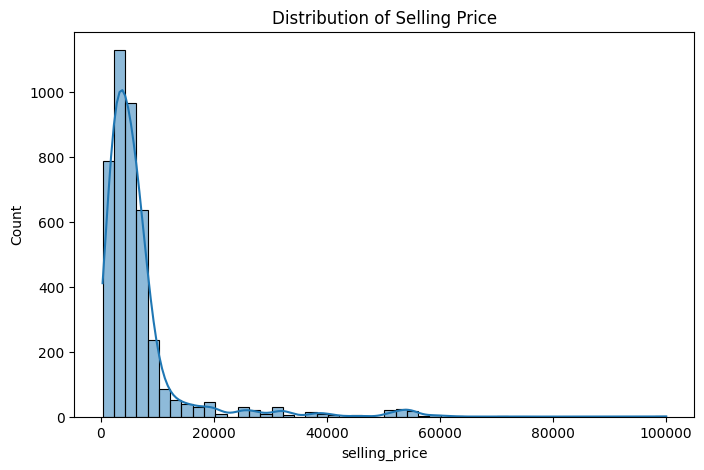

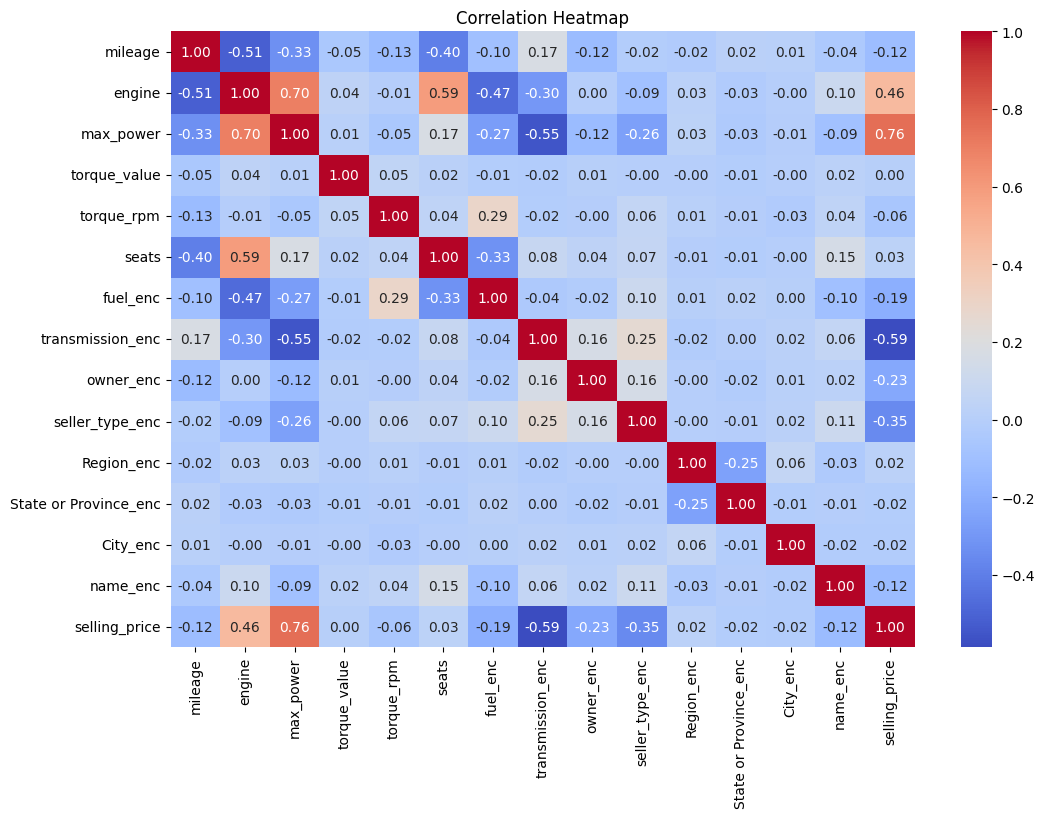

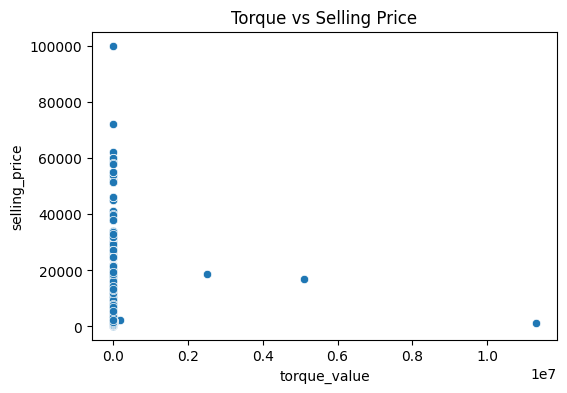

In [59]:
# Statistik deskriptif
print(df[feature_cols + [target]].describe())

# Distribusi harga
plt.figure(figsize=(8,5))
sns.histplot(df[target], bins=50, kde=True)
plt.title('Distribution of Selling Price')
plt.show()

# Korelasi
plt.figure(figsize=(12,8))
corr = df[feature_cols + [target]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

# Scatterplot contoh: torque_value vs selling_price
plt.figure(figsize=(6,4))
sns.scatterplot(x='torque_value', y=target, data=df)
plt.title('Torque vs Selling Price')
plt.show()

# 2B. Build an Artificial Neural Network (ANN) with 3 hidden layers. Each hidden layer should use sigmoid as its activation function. The number of neurons in the first hidden layer should be 512 and each of the subsequent layers will have N/2 neurons where N is the number of neurons in the previous layer. Train the model for at least 20 epochs & analyze the train-validation losses!

In [60]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
import matplotlib.pyplot as plt

In [61]:
# Misal df sudah siap, feature_cols & target sudah ada
X = df[feature_cols].values
y = df[target].values.reshape(-1,1)

# Train-test split
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)
x_val, x_test, y_val, y_test = train_test_split(x_test, y_test, test_size = 0.5, random_state = 42)

scalerX = StandardScaler()
x_train = scalerX.fit_transform(x_train)
x_val = scalerX.transform(x_val)
x_test = scalerX.transform(x_test)

scalerY = StandardScaler()
y_train = scalerY.fit_transform(y_train)
y_val   = scalerY.transform(y_val)
y_test  = scalerY.transform(y_test)

In [62]:
# Build ANN
model_b = Sequential()
model_b.add(Dense(512, input_dim=x_train.shape[1], activation='sigmoid'))
model_b.add(BatchNormalization()) #BatchNormalization ditambahkan untuk menstabilkan input untuk sigmoid
model_b.add(Dropout(0.3)) #dropout mencegah overfitting
model_b.add(Dense(256, activation='sigmoid'))
model_b.add(BatchNormalization())
model_b.add(Dropout(0.2))
model_b.add(Dense(128, activation='sigmoid'))
model_b.add(BatchNormalization())

model_b.add(Dense(1, activation='linear'))

# Compile
model_b.compile(optimizer=Adam(learning_rate=0.001), loss='mse')

# Train
history = model_b.fit(x_train, y_train, validation_data=(x_val, y_val),
                    epochs=20, batch_size=32)


Epoch 1/20


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 1.3059 - val_loss: 1.0955
Epoch 2/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4153 - val_loss: 0.9559
Epoch 3/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3219 - val_loss: 0.7393
Epoch 4/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3443 - val_loss: 0.3402
Epoch 5/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2840 - val_loss: 0.2279
Epoch 6/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3001 - val_loss: 0.2571
Epoch 7/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.2171 - val_loss: 0.3026
Epoch 8/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2398 - val_loss: 0.2355
Epoch 9/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1971 - val_loss: 0.2503
Epoch 10/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1913 - val_loss: 0.2281
Epoch 11/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2151 - val_loss: 0.2582
Epoch 12/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1756 - val_loss: 0.2396


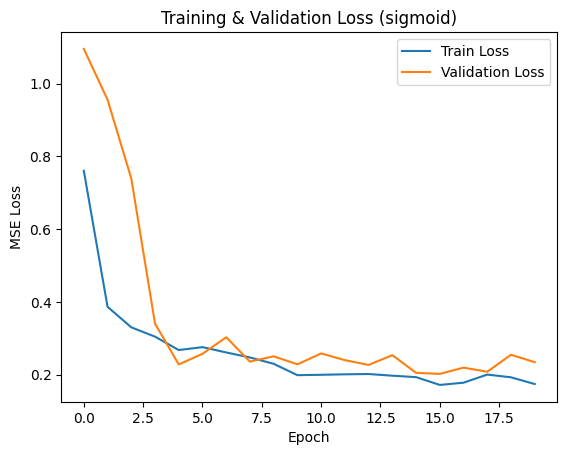

In [63]:
# Plot train-validation loss
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Training & Validation Loss (sigmoid)')
plt.legend()
plt.show()

1. Train Loss (biru) menurun dari ~0.8 ke ~17.5 di akhir.

2. Validation Loss (oranye) menurun awalnya, tapi mulai naik lagi setelah epoch ~4.

3. Ada gap yang jelas antara training loss dan validation loss di akhir yang merupakan tanda overfitting.

Kesimpulan :

Model dengan sigmoid belajar tapi tidak se-stabil ReLU.

Validation loss naik di epoch akhir, aritnya model mulai overfit ke training data, performa validation menurun.

Fluktuasi lebih besar dibanding ReLU, kemungkinan karena sigmoid memiliki gradient vanishing di layer tersembunyi sehingga learning lebih lambat dan kurang stabil.

# 2C. Modify the architecture of the ANN model or fine-tune it to obtain a model with lower best validation loss. Explain the reasons behind your modifications!

In [100]:
# Build ANN
model_c = Sequential()
model_c.add(Dense(512, input_dim=x_train.shape[1], activation='relu'))
model_c.add(BatchNormalization())
model_c.add(Dropout(0.3))
model_c.add(Dense(256, activation='relu'))
model_c.add(BatchNormalization())
model_c.add(Dropout(0.2))
model_c.add(Dense(128, activation='relu'))
model_c.add(BatchNormalization())

model_c.add(Dense(1, activation='linear'))

# Compile
model_c.compile(optimizer=Adam(learning_rate=0.0005), loss='mse')

# Train
history = model_c.fit(x_train, y_train, validation_data=(x_val, y_val),
                    epochs=20, batch_size=24)

Epoch 1/20
123/123 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 1.4818 - val_loss: 0.8025
Epoch 2/20
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.6384 - val_loss: 0.5899
Epoch 3/20
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.4573 - val_loss: 0.7622
Epoch 4/20
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3936 - val_loss: 0.8237
Epoch 5/20
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3850 - val_loss: 1.1505
Epoch 6/20
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3258 - val_loss: 1.0260
Epoch 7/20
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2781 - val_loss: 0.7491
Epoch 8/20
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.2804 - val_loss: 0.5718
Epoch 9/20
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2932 - val_loss: 1.0459
Epoch 10/20
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2399 - val_loss: 0.3739
Epoch 11/20
123/123 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2348 - val_loss: 0.7841
Epoch 12/20
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step

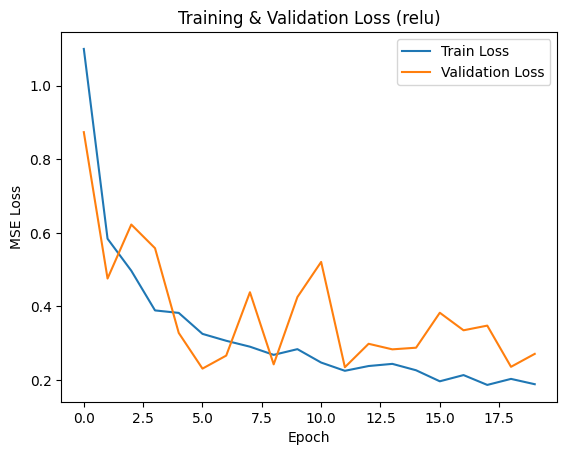

In [97]:
# Plot train-validation loss
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Training & Validation Loss (relu)')
plt.legend()
plt.show()

1. Train Loss (biru) cepat menurun di awal (epoch 0–5) dari sekitar 1.2 ke ~0.3, kemudian stabil sekitar 0.2 di akhir.

2. Validation Loss (oranye) juga menurun cepat awalnya, tapi terlihat ada sedikit fluktuasi setelah epoch ~7, kemudian stabil di ~0.2–0.3.

3. Tidak terlihat perbedaan besar antara training dan validation loss di akhir (tidak ada overfitting yang signifikan).

Kesimpulan :

Model belajar dengan baik menggunakan ReLU; loss menurun stabil.

Performa model pada data training dan validation relatif mirip, artinya model tidak overfitting.

Fluktuasi minor di validation loss bisa karena ukuran dataset validation relatif kecil atau noise.

Loss akhir cukup rendah (~0.2), menandakan model sudah cukup fit ke data.

#2D. Evaluate both models on a test dataset. Analyze the results & make a clear conclusion!

In [66]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [83]:
# 1. Dapatkan prediksi dari X_test (hasilnya masih di-scale 0-1)
y_pred_scaled_b = model_b.predict(x_test)

# 2. Kembalikan ke skala harga asli (misal: USD)
y_pred_b = scalerY.inverse_transform(y_pred_scaled_b)
# y_test_orig juga harus di-inverse-transform dari y_test
y_test_orig = scalerY.inverse_transform(y_test)

# 3. Hitung Metrik
r2_b = r2_score(y_test_orig, y_pred_b)
rmse_b = np.sqrt(mean_squared_error(y_test_orig, y_pred_b))
mae_b = mean_absolute_error(y_test_orig, y_pred_b)

print("Hasil Model (b) Sigmoid:")
print(f"  R-squared (R²): {r2_b:.4f}")
print(f"  RMSE: {rmse_b:.2f}")
print(f"  MAE: {mae_b:.2f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Hasil Model (b) Sigmoid:
  R-squared (R²): 0.8274
  RMSE: 3567.86
  MAE: 1851.19


In [101]:
# 1. Dapatkan prediksi dari X_test (hasilnya masih di-scale 0-1)
y_pred_scaled_c = model_c.predict(x_test)

# 2. Kembalikan ke skala harga asli (misal: USD)
y_pred_c = scalerY.inverse_transform(y_pred_scaled_c)
# y_test_orig juga harus di-inverse-transform dari y_test
y_test_orig = scalerY.inverse_transform(y_test)

# 3. Hitung Metrik
r2_c = r2_score(y_test_orig, y_pred_c)
rmse_c = np.sqrt(mean_squared_error(y_test_orig, y_pred_c))
mae_c = mean_absolute_error(y_test_orig, y_pred_c)

print("Hasil Model (c) ReLU:")
print(f"  R-squared (R²): {r2_c:.4f}")
print(f"  RMSE: {rmse_c:.2f}")
print(f"  MAE: {mae_c:.2f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
Hasil Model (c) ReLU:
  R-squared (R²): 0.8582
  RMSE: 3233.57
  MAE: 1779.18


**Model Sigmoid**

R-squared (R²): 0.8274
Menunjukkan sekitar 82,74% variasi data target dapat dijelaskan oleh model. Artinya, model sigmoid cukup baik dalam menangkap pola hubungan antara fitur dan target.

RMSE: 3567.86
Mengukur rata-rata kesalahan prediksi. Nilai ini berarti prediksi model biasanya menyimpang sekitar ±3567.86 unit dari nilai aktual.

MAE: 1851.19
Menunjukkan rata-rata kesalahan absolut prediksi. Nilai ini lebih rendah daripada RMSE karena MAE tidak memberi bobot lebih pada kesalahan besar.

Kesimpulan:
Model sigmoid cukup baik, dengan kemampuan prediksi yang tinggi dan kesalahan prediksi masih dalam batas wajar.

Kesimpulan :

Model sigmoid cukup baik, memiliki kemampuan prediksi yang tinggi dan kesalahan prediksi masih dalam batas wajar.

**Model ReLU**

R-squared (R²): 0.8582
Model ReLU menjelaskan sekitar 85,82% variasi data target, sedikit lebih tinggi dari model sigmoid, sehingga mampu menangkap pola data dengan baik.

RMSE: 3233.57
Mengukur rata-rata kesalahan prediksi. Nilai RMSE lebih rendah dibanding sigmoid, menunjukkan prediksi model lebih dekat ke nilai aktual secara keseluruhan.

MAE: 1779.18
Menunjukkan rata-rata kesalahan absolut prediksi. Sedikit lebih tinggi dari sigmoid, menunjukkan kesalahan rata-rata prediksi sedikit lebih besar.

Kesimpulan:
Model ReLU cukup baik, dengan prediksi rata-rata dekat nilai aktual (RMSE lebih rendah), meskipun kesalahan absolut rata-rata sedikit lebih tinggi. Secara umum, model ReLU sedikit lebih unggul dalam menjelaskan variasi data.